In [1]:
import sys
src_path = "/home/souvik/codes/foresee-main"
sys.path.append(src_path)

import numpy as np
import os
from matplotlib import pyplot as plt
import math
import random
from skhep.math.vectors import LorentzVector, Vector3D
from scipy import interpolate
from matplotlib import gridspec
import os, inspect

In [2]:
from src_modified.foresee import Foresee, Utility, Model
foresee = Foresee()

energy = "100"
modelname="U1_slzplln_faser"
model = Model(modelname, path="./")

In [3]:
sys.path.insert(1, os.path.join(os.path.dirname(os.path.realpath(
                inspect.getfile(inspect.currentframe()))), "/home/souvik/codes/darkcast_chiral/"))
import darkcast 

In [4]:
model.add_production_2bodydecay(
    pid0 = "111",
    pid1 = "22",
    br = "2*0.99 * (coupling/0.303)**2 * pow(1.-pow(mass/self.masses('111'),2),3)",
#     br = "2*0.99 * (coupling)**2 * pow(1.-pow(mass/self.masses('111'),2),3)",
    generator = "EPOSLHC",
    energy = energy,
    nsample = 50
)

model.add_production_2bodydecay(
    pid0 = "221",
    pid1 = "22",
    br = "2*0.25*0.39  * (coupling/0.303)**2 * pow(1.-pow(mass/self.masses('221'),2),3)",
#     br = "2*0.39 * (coupling)**2 * pow(1.-pow(mass/self.masses('221'),2),3)",
    generator = "EPOSLHC",
    energy = energy,
    nsample = 50, 
)

In [5]:
masses_brem = [ 
   0.01  ,  0.0126,  0.0158,  0.02  ,  0.0251,  0.0316,  0.0398,
   0.0501,  0.0631,  0.0794,  0.1   ,  0.1122,  0.1259,  0.10013,
   0.1585,  0.1778,  0.1995,  0.2239,  0.2512,  0.2818,  0.3162,
   0.3548,  0.3981,  0.4467,  0.5012,  0.5623,  0.6026,  0.631 ,
   0.6457,  0.6607,  0.6761,  0.6918,  0.7079,  0.7244,  0.7413,
   0.7586,  0.7762,  0.7943,  0.8128,  0.8318,  0.8511,  0.871 ,
   0.8913,  0.912 ,  0.9333,  0.955 ,  0.9772,  1.    ,  1.122 ,
   1.2589,  1.4125,  1.5849,  1.7783,  1.9953,  2.2387,  2.5119,
   2.8184,  3.1623,  3.9811,  5.0119,  6.3096,  7.9433, 10.    
]

model.add_production_direct(
    label = "Brem",
    energy = energy,
    condition = None, #"1./0.3**2 * (p.pt<1)",
#     condition = "p.pt<1",
    coupling_ref=1,
    masses = masses_brem,
)

In [6]:
masses1 = np.logspace(-3, np.log10(4), 60)
masses2 = np.logspace(np.log10(4),np.log10(6), 40)
masses3 = np.logspace(np.log10(6), 1, 10)
masses = np.array(sorted(list(set(np.concatenate((masses1,masses2,masses3))))))
foresee.set_model(model=model)
# for mass in masses:
#     foresee.get_llp_spectrum(mass=mass, coupling=1, luminosity=3000, mincount=0,
#                                           do_plot=False, stat_cuts=None, save_file=True)

In [7]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<10 and abs(x.y)<10", 400, 30000
energy, setup, name = '100', "default", "U1_X"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.mix_event_gen(masses, energy, N=1, modes=None, nsample=10, Us=np.logspace(-6,0,70), sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(200)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 14min 58s, sys: 327 ms, total: 14min 58s
Wall time: 14min 59s


In [8]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-1, model1="U1_X_1n", model0="B-L_boson", energy=energy,
                                    coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 288 ms, sys: 20 ms, total: 308 ms
Wall time: 316 ms


/home/souvik/anaconda3/lib/python3.11/site-packages/numpy/lib/npyio.py:521: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr = np.asanyarray(arr)


In [9]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH = -1.2, model1="U1_X_12n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH = 0, model1="U1_X_0", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_40370/2081264103.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


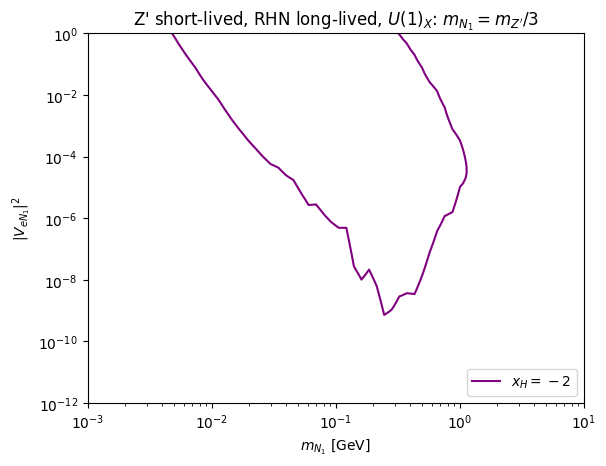

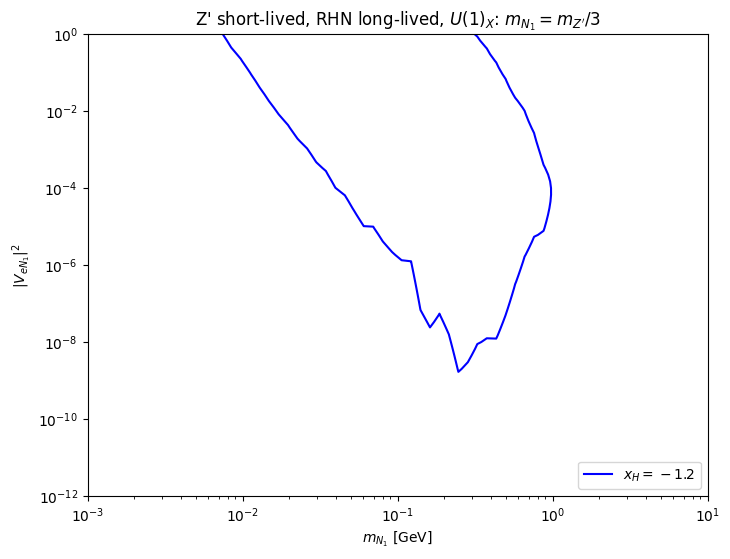

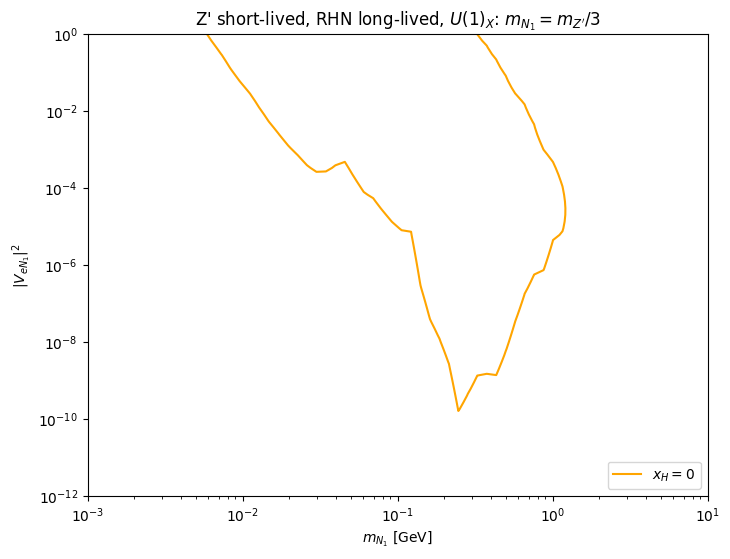

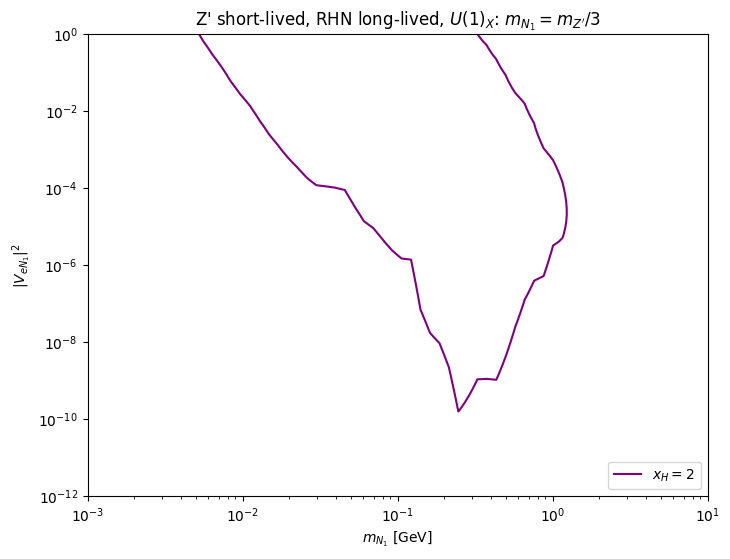

In [10]:
setups = [
         ["100TeV_default2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_default12n.npy",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_default0.npy",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000],  
         ["100TeV_default2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3U_e/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses/3, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{N_1}$ [GeV]") 
    ax.set_ylabel(r"$|V_{eN_1}|^2$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-12, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, $U(1)_X$: $m_{N_1} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3U_e/plots/"+filename+".png")

In [11]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<10 and abs(x.y)<10", 400, 30000
energy, setup, name = '100', "default_LLP2_", "U1_X"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.mix_event_gen(masses, energy, N=2, modes=None, nsample=10, Us=np.logspace(-8,0,70), sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(200)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 14min 56s, sys: 120 ms, total: 14min 56s
Wall time: 14min 57s


In [12]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-1, model1="U1_X_1n", model0="B-L_boson", energy=energy,
                                    coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 316 ms, sys: 12 ms, total: 328 ms
Wall time: 334 ms


In [13]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH = -1.2, model1="U1_X_12n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH = 0, model1="U1_X_0", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_40370/4060920354.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


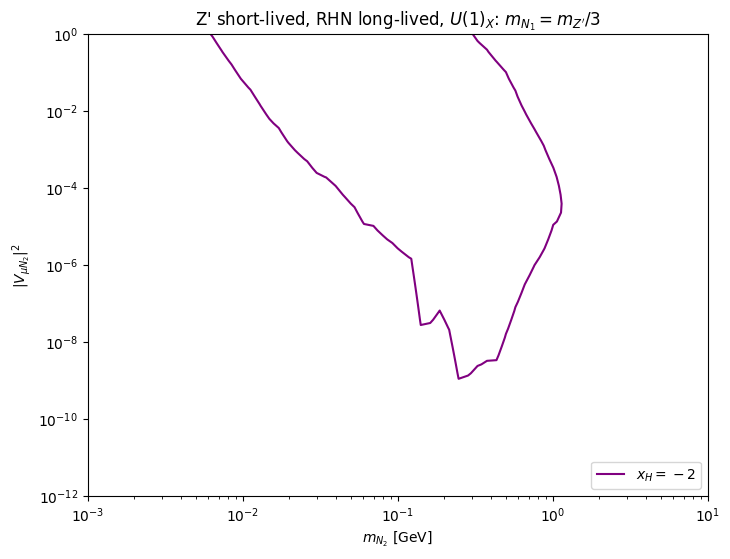

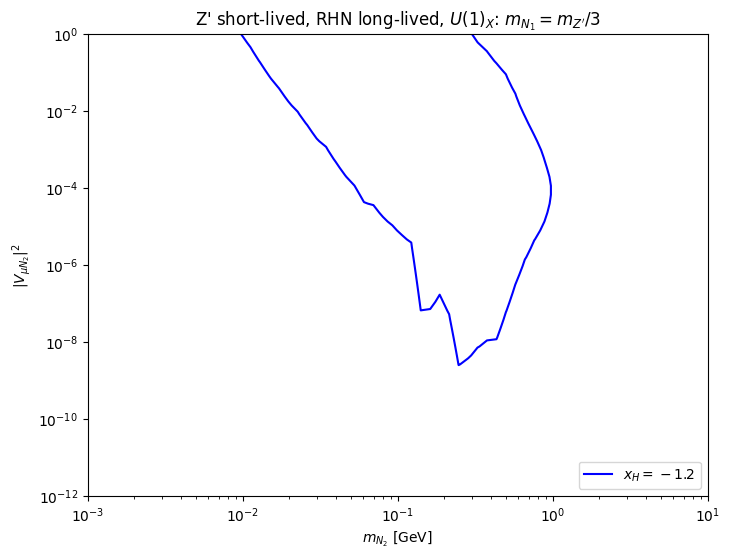

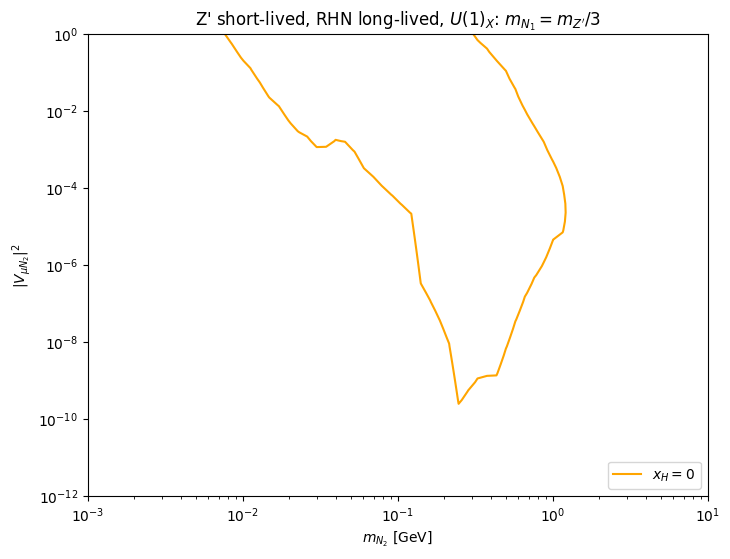

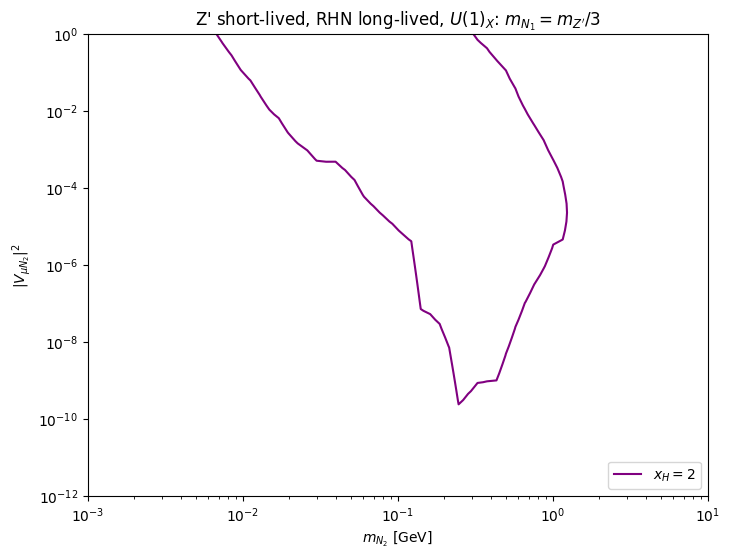

In [14]:
setups = [
         ["100TeV_default_LLP2_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP2_12n.npy",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP2_0.npy",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000],  
         ["100TeV_default_LLP2_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3U_mu/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses/3, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{N_2}$ [GeV]") 
    ax.set_ylabel(r"$|V_{\mu N_2}|^2$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-12, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, $U(1)_X$: $m_{N_1} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3U_mu/plots/"+filename+".png")

In [15]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<10 and abs(x.y)<10", 400, 30000
energy, setup, name = '100', "alternative_LLP2_", "U1_X_phi4"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.mix_event_gen(masses, energy, N=1, modes=None, nsample=10, Us=np.logspace(-6,0,70), sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(200)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 15min 3s, sys: 87.9 ms, total: 15min 3s
Wall time: 15min 4s


In [16]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-1, model1="U1_X_phi4_1n", model0="B-L_boson", energy=energy,
                                    coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 273 ms, sys: 28 ms, total: 301 ms
Wall time: 300 ms


In [17]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-2, model1="U1_X_phi4_2n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH = -1.2, model1="U1_X_phi4_12n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH = 0, model1="U1_X_phi4_0", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH=2, model1="U1_X_phi4_2p", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_40370/232285915.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


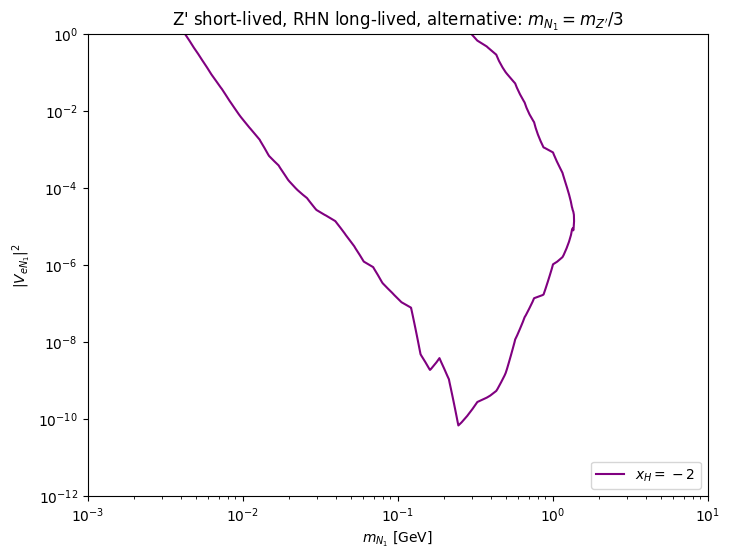

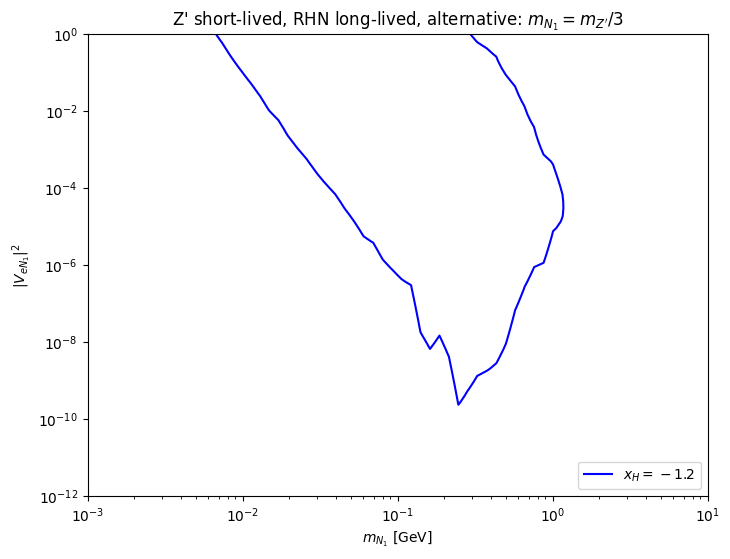

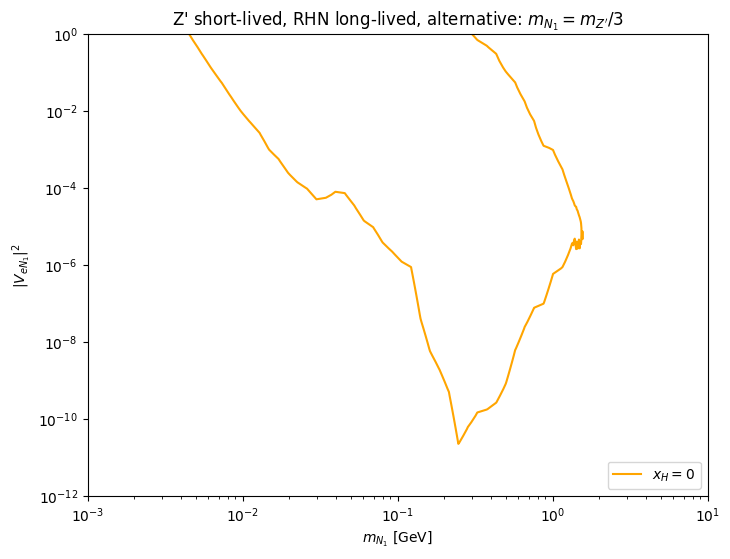

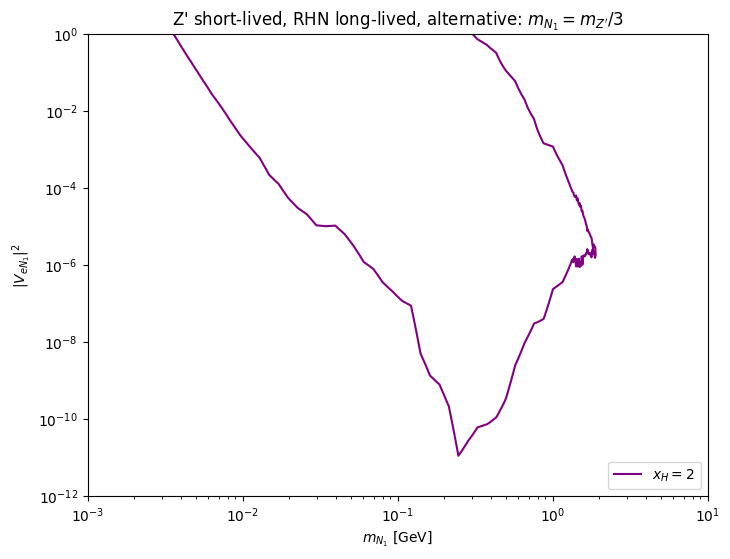

In [18]:
setups = [
         ["100TeV_alternative_LLP2_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP2_12n.npy",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP2_0.npy",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000],  
         ["100TeV_alternative_LLP2_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3U_e/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses/3, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{N_1}$ [GeV]") 
    ax.set_ylabel(r"$|V_{eN_1}|^2$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-12, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, alternative: $m_{N_1} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3U_e/plots/"+filename+".png")

In [19]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<10 and abs(x.y)<10", 400, 30000
energy, setup, name = '100', "alternative_LLP2_", "U1_X_phi4"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.mix_event_gen(masses, energy, N=2, modes=None, nsample=10, Us=np.logspace(-6,0,70), sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(200)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 14min 59s, sys: 35.9 ms, total: 14min 59s
Wall time: 14min 59s


In [20]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-1, model1="U1_X_phi4_1n", model0="B-L_boson", energy=energy,
                                    coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 289 ms, sys: 8 ms, total: 297 ms
Wall time: 297 ms


In [21]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-2, model1="U1_X_phi4_2n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH = -1.2, model1="U1_X_phi4_12n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH = 0, model1="U1_X_phi4_0", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH=2, model1="U1_X_phi4_2p", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_40370/1857545969.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


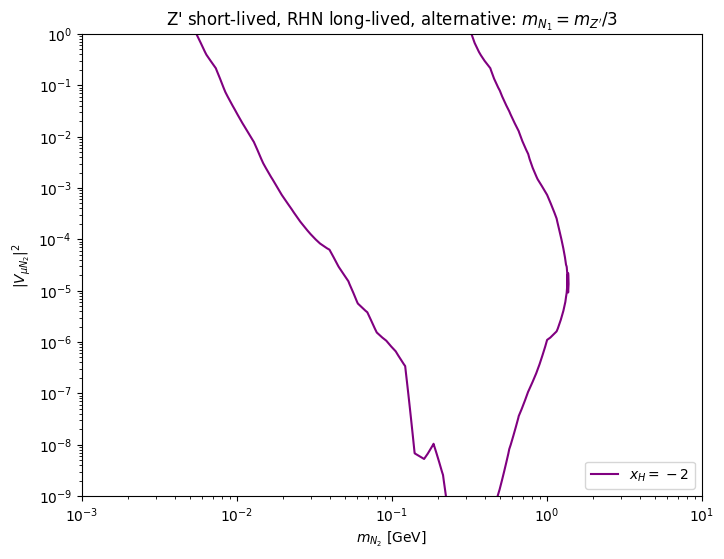

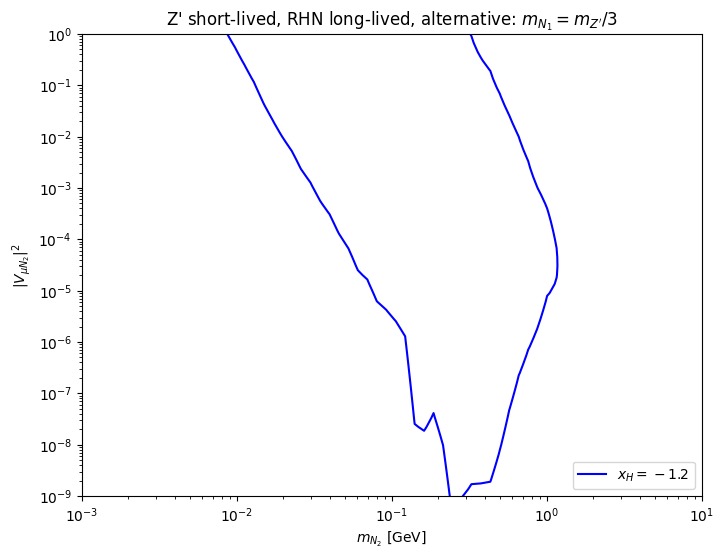

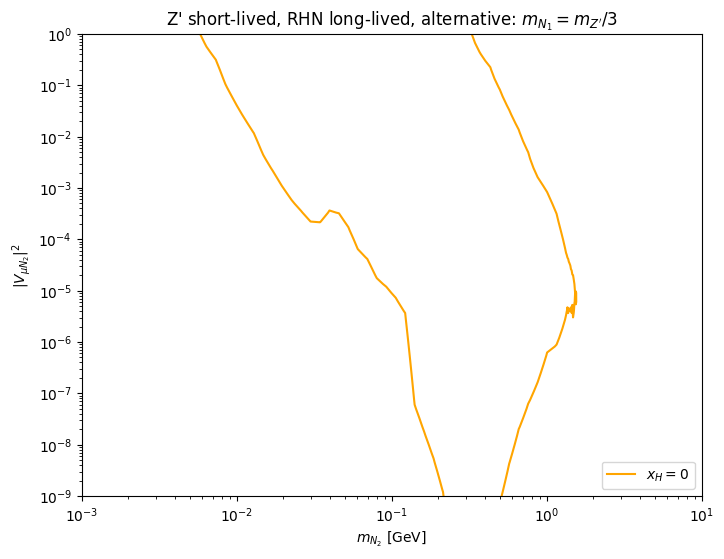

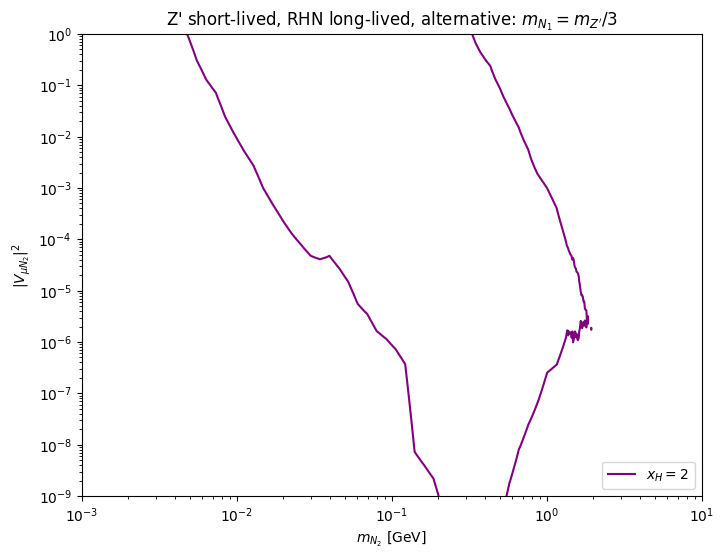

In [22]:
setups = [
         ["100TeV_alternative_LLP2_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP2_12n.npy",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP2_0.npy",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000],  
         ["100TeV_alternative_LLP2_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3U_mu/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses/3, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{N_2}$ [GeV]") 
    ax.set_ylabel(r"$|V_{\mu N_2}|^2$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-9, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, alternative: $m_{N_1} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3U_mu/plots/"+filename+".png")

In [23]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<2.5 and abs(x.y)<2.5", 50, 30000
energy, setup, name = '100', "default_LLP1_", "U1_X"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.mix_event_gen(masses, energy, N=1, modes=None, nsample=10, Us=np.logspace(-6,0,70), sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(12.5)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 12min 36s, sys: 36.1 ms, total: 12min 36s
Wall time: 12min 36s


In [24]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-1, model1="U1_X_1n", model0="B-L_boson", energy=energy,
                                    coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 301 ms, sys: 12 ms, total: 313 ms
Wall time: 313 ms


In [25]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH = -1.2, model1="U1_X_12n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH = 0, model1="U1_X_0", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_40370/1699176209.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


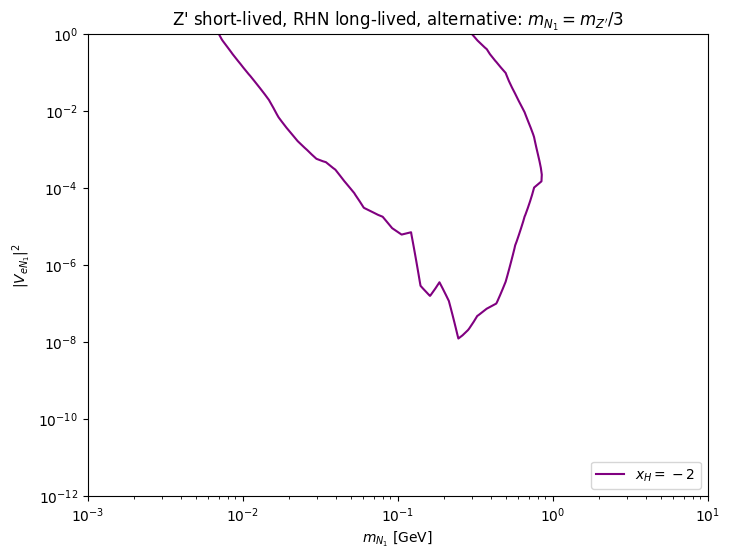

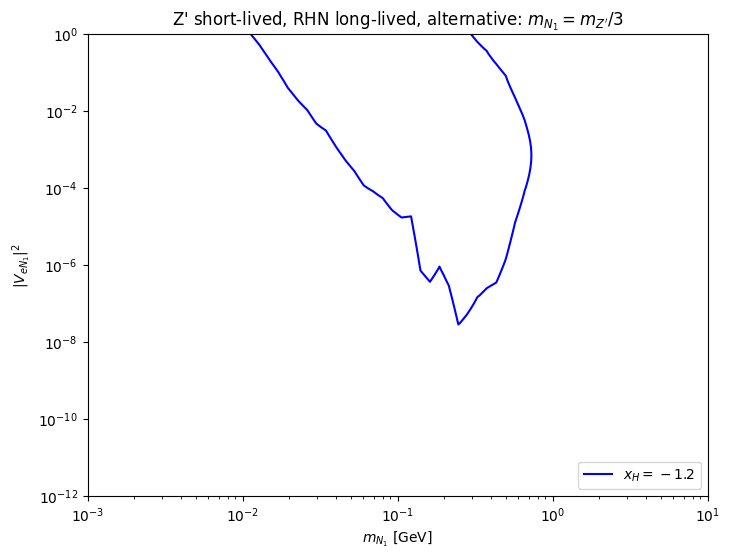

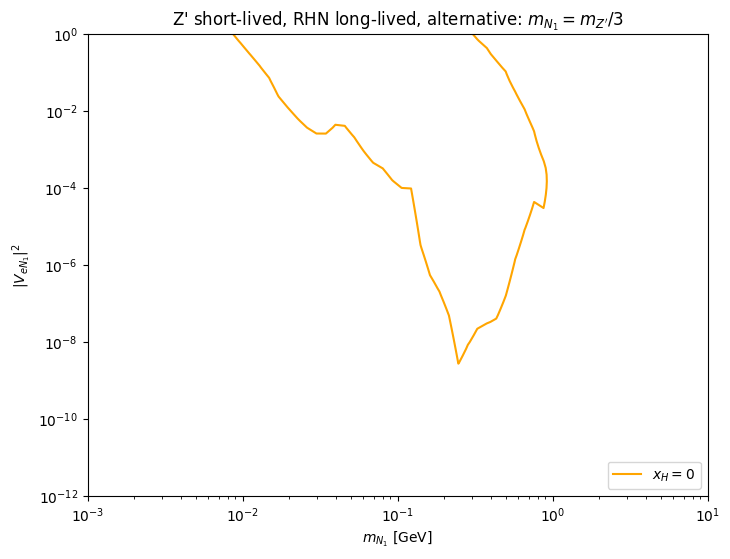

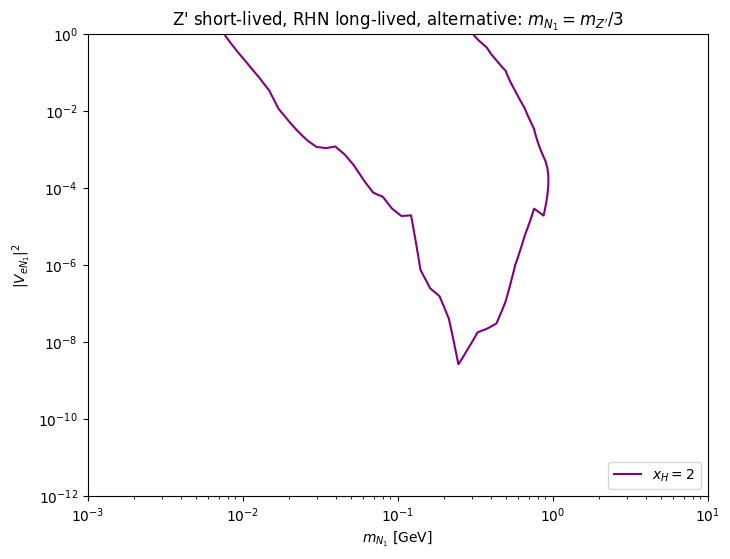

In [26]:
setups = [
         ["100TeV_default_LLP1_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP1_12n.npy",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP1_0.npy",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000],  
         ["100TeV_default_LLP1_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3U_e/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses/3, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{N_1}$ [GeV]") 
    ax.set_ylabel(r"$|V_{eN_1}|^2$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-12, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, alternative: $m_{N_1} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3U_e/plots/"+filename+".png")

In [27]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<2.5 and abs(x.y)<2.5", 50, 30000
energy, setup, name = '100', "default_LLP1_", "U1_X"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.mix_event_gen(masses, energy, N=2, modes=None, nsample=10, Us=np.logspace(-6,0,70), sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(12.5)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 12min 43s, sys: 28 ms, total: 12min 43s
Wall time: 12min 44s


In [28]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-1, model1="U1_X_1n", model0="B-L_boson", energy=energy,
                                    coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 294 ms, sys: 24 ms, total: 318 ms
Wall time: 318 ms


In [29]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH = -1.2, model1="U1_X_12n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH = 0, model1="U1_X_0", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_40370/3686046812.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


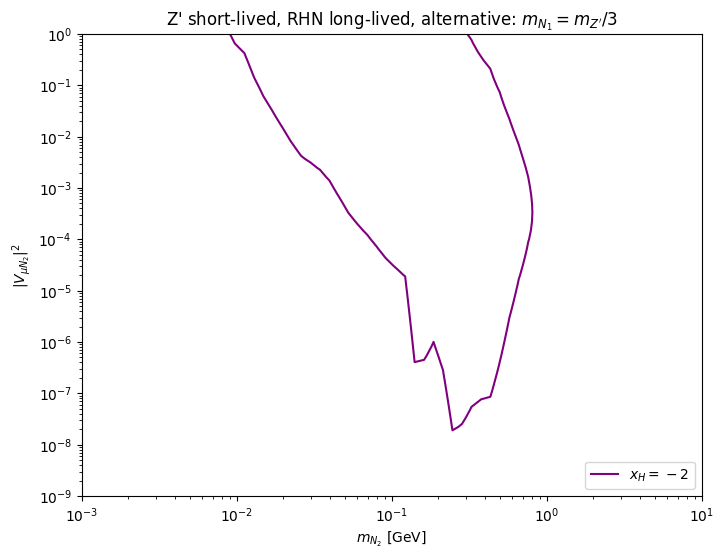

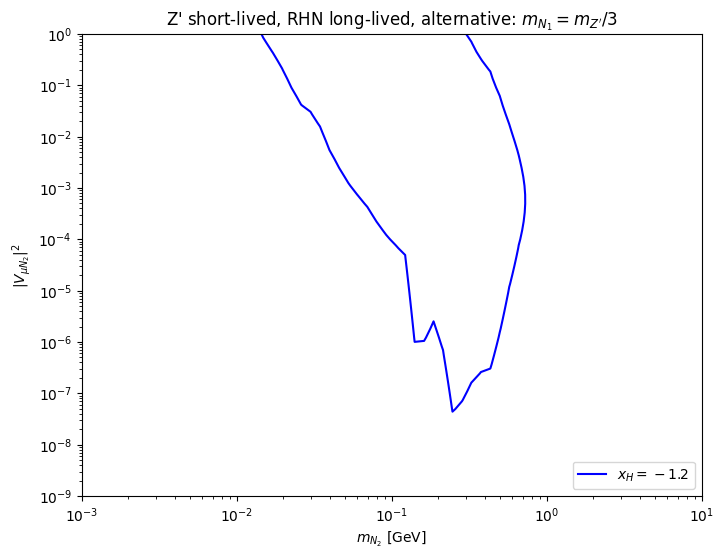

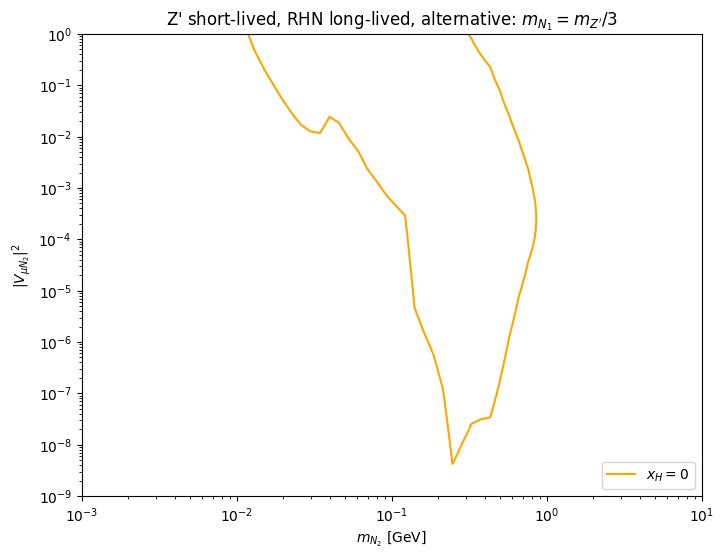

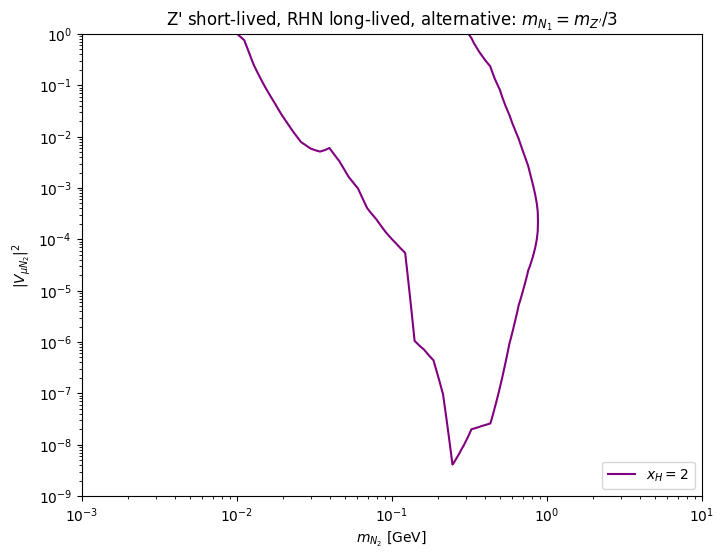

In [30]:
setups = [
         ["100TeV_default_LLP1_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP1_12n.npy",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP1_0.npy",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000],  
         ["100TeV_default_LLP1_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3U_mu/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses/3, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{N_2}$ [GeV]") 
    ax.set_ylabel(r"$|V_{\mu N_2}|^2$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-9, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, alternative: $m_{N_1} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3U_mu/plots/"+filename+".png")

In [31]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<2.5 and abs(x.y)<2.5", 50, 30000
energy, setup, name = '100', "alternative_LLP1_", "U1_X_phi4"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.mix_event_gen(masses, energy, N=1, modes=None, nsample=10, Us=np.logspace(-6,0,70), sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(12.5)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 12min 39s, sys: 40 ms, total: 12min 39s
Wall time: 12min 39s


In [32]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-1, model1="U1_X_phi4_1n", model0="B-L_boson", energy=energy,
                                    coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 297 ms, sys: 16 ms, total: 313 ms
Wall time: 312 ms


In [33]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-2, model1="U1_X_phi4_2n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH = -1.2, model1="U1_X_phi4_12n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH = 0, model1="U1_X_phi4_0", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH=2, model1="U1_X_phi4_2p", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_e/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_40370/232285915.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


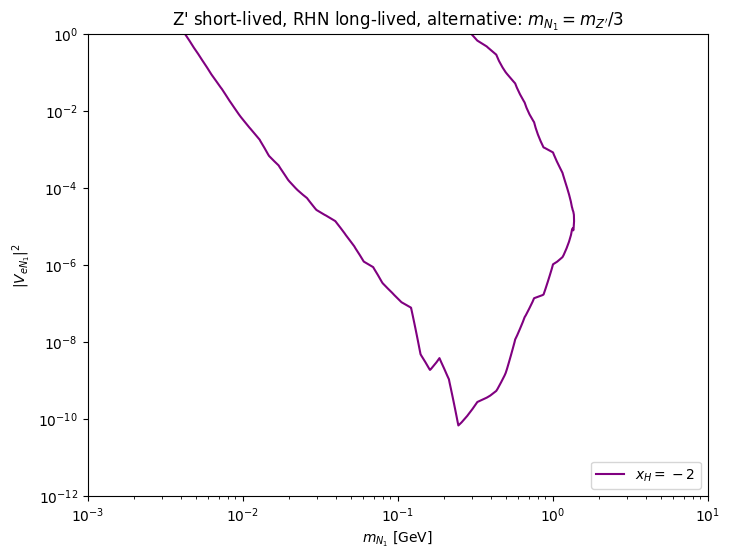

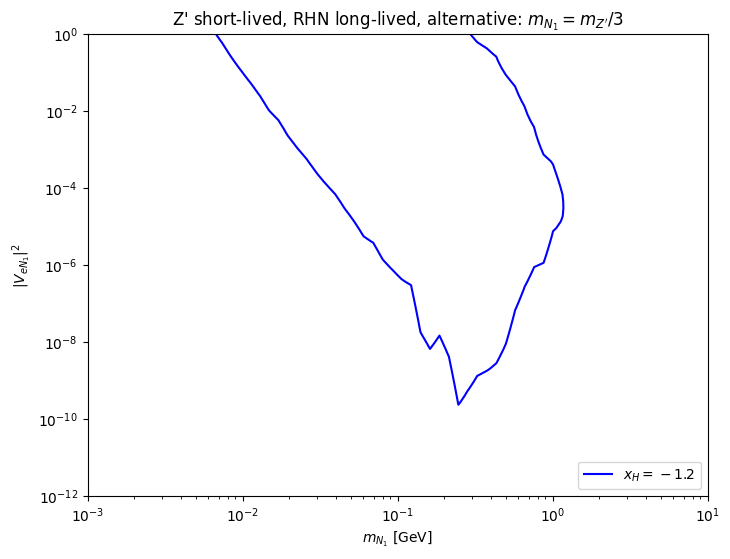

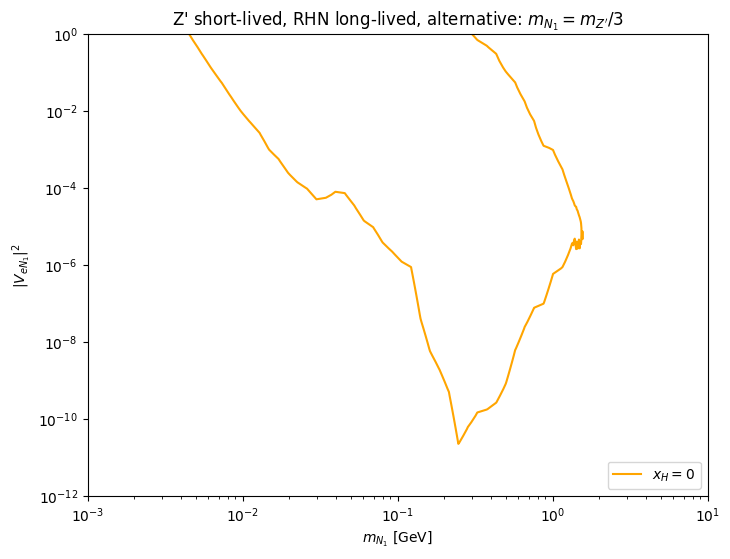

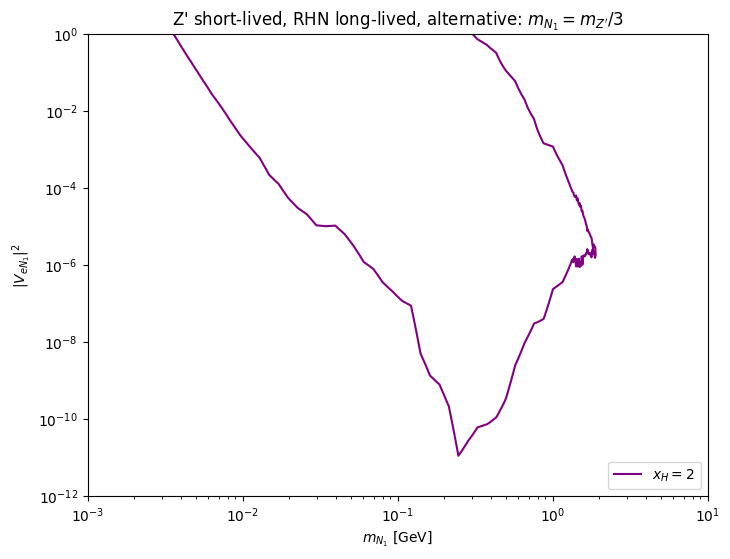

In [34]:
setups = [
         ["100TeV_alternative_LLP2_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP2_12n.npy",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP2_0.npy",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000],  
         ["100TeV_alternative_LLP2_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3U_e/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses/3, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{N_1}$ [GeV]") 
    ax.set_ylabel(r"$|V_{eN_1}|^2$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-12, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, alternative: $m_{N_1} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3U_e/plots/"+filename+".png")

In [35]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<2.5 and abs(x.y)<2.5", 50, 30000
energy, setup, name = '100', "alternative_LLP1_", "U1_X_phi4"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.mix_event_gen(masses, energy, N=2, modes=None, nsample=10, Us=np.logspace(-6,0,70), sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(12.5)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 12min 36s, sys: 71.9 ms, total: 12min 36s
Wall time: 12min 37s


In [36]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-1, model1="U1_X_phi4_1n", model0="B-L_boson", energy=energy,
                                    coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])


CPU times: user 295 ms, sys: 20 ms, total: 315 ms
Wall time: 315 ms


In [37]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH=-2, model1="U1_X_phi4_2n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_mix(nsample=10, mass=mass, xH = -1.2, model1="U1_X_phi4_12n", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH = 0, model1="U1_X_phi4_0", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_mix(nsample=10, mass=mass, xH=2, model1="U1_X_phi4_2p", model0="B-L_boson", energy=energy,
#                                     coup = 1e-4, mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3U_mu/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_40370/506870369.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


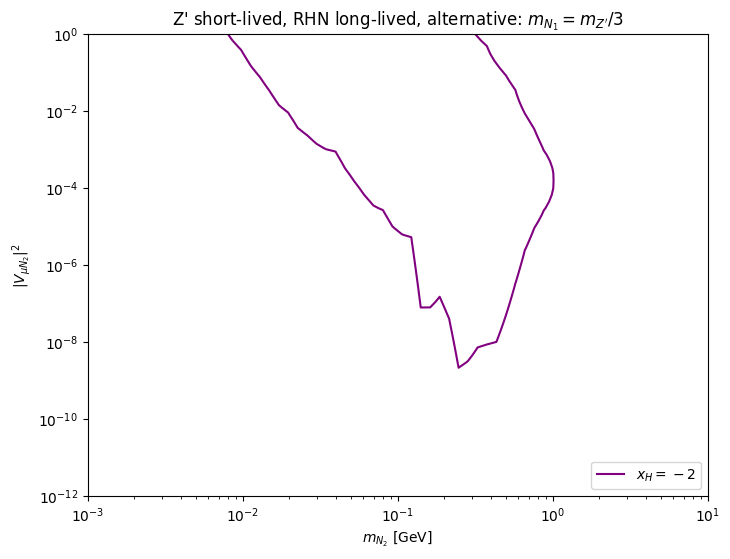

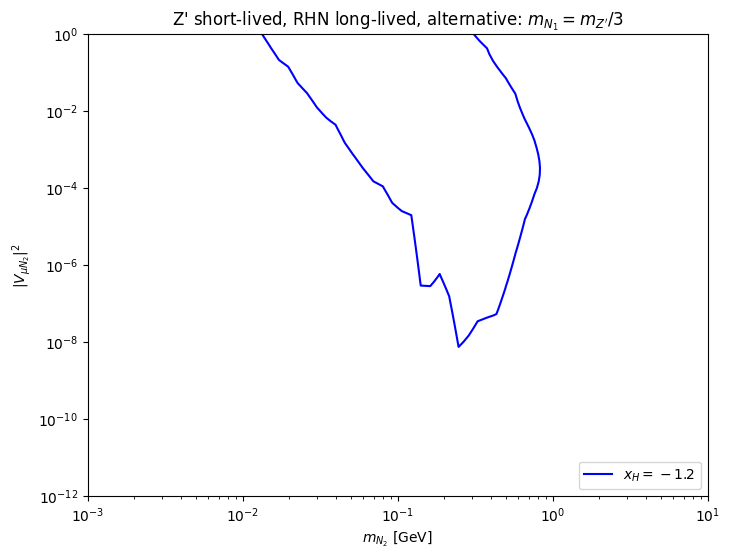

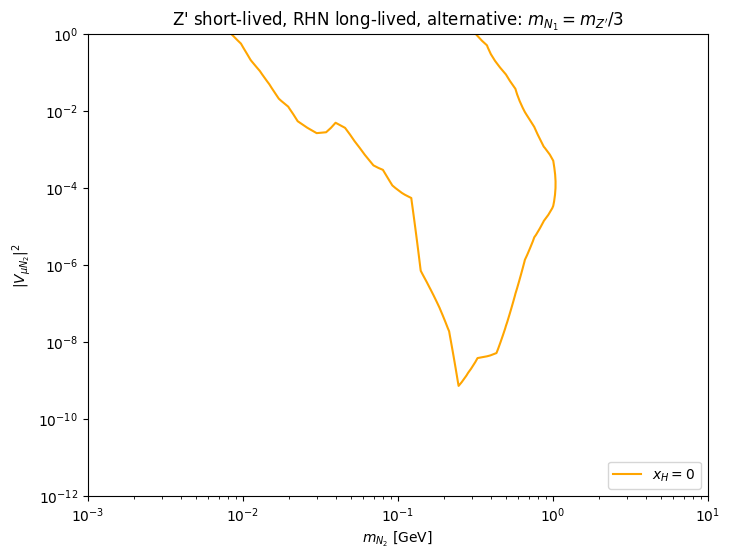

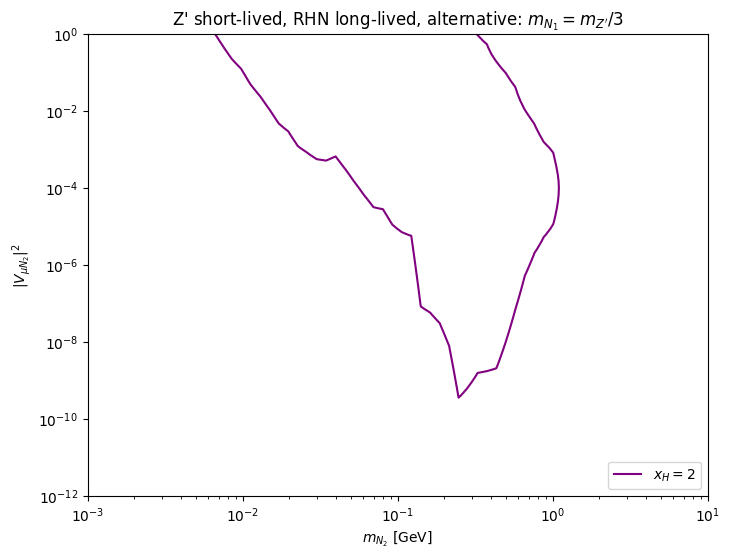

In [38]:
setups = [
         ["100TeV_alternative_LLP1_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP1_12n.npy",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP1_0.npy",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000],  
         ["100TeV_alternative_LLP1_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3U_mu/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses/3, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{N_2}$ [GeV]") 
    ax.set_ylabel(r"$|V_{\mu N_2}|^2$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-12, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, alternative: $m_{N_1} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3U_mu/plots/"+filename+".png")